# 04-638 Analytics Assignment I: EDA of GDP per capita, Unemployment and Life Expectancy
**Scope of this notebook:** Preliminary Questions 1 to 4 (individual section). Data: World Bank World Development Indicators, 2000 to 2024, all countries (combined file `All_three_combined.csv`).
**Indicators:** GDP per capita (current US$) `NY.GDP.PCAP.CD`; Unemployment, total (% of total labor force) (national estimate) `SL.UEM.TOTL.NE.ZS`; Life expectancy at birth (years) `SP.DYN.LE00.IN`.


## 1. Load and reshape the data
The source file is in World Bank wide format (one row per country and indicator, one column per year). It is reshaped to one row per country and year, with one column per indicator. World Bank aggregates (regions, income groups) are removed so that only countries remain.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
SRC = "All_three_combined.csv"   # place the file next to this notebook

raw = pd.read_csv(SRC, na_values=[".."])
year_cols = [c for c in raw.columns if c[:4].isdigit()]
raw = raw.rename(columns={c: c[:4] for c in year_cols})
years = [c[:4] for c in year_cols]

long = raw.melt(id_vars=["Country Name", "Country Code", "Series Code"],
                value_vars=years, var_name="year", value_name="value")
long["year"] = long["year"].astype(int)
panel = (long.pivot_table(index=["Country Name", "Country Code", "year"],
                          columns="Series Code", values="value")
             .reset_index())
panel.columns.name = None
panel = panel.rename(columns={"NY.GDP.PCAP.CD": "gdp", "SL.UEM.TOTL.NE.ZS": "unemp",
                              "SP.DYN.LE00.IN": "le"})

AGGREGATES = {
    "Africa Eastern and Southern", "Africa Western and Central", "Arab World",
    "Caribbean small states", "Central Europe and the Baltics", "Early-demographic dividend",
    "East Asia & Pacific", "East Asia & Pacific (IDA & IBRD countries)",
    "East Asia & Pacific (excluding high income)", "Euro area", "Europe & Central Asia",
    "Europe & Central Asia (IDA & IBRD countries)", "Europe & Central Asia (excluding high income)",
    "European Union", "Fragility, Conflict, and Violence (FCV) situations",
    "Heavily indebted poor countries (HIPC)", "High income", "IBRD only", "IDA & IBRD total",
    "IDA blend", "IDA only", "IDA total", "Latin America & Caribbean",
    "Latin America & Caribbean (excluding high income)",
    "Latin America & the Caribbean (IDA & IBRD countries)", "Late-demographic dividend",
    "Least developed countries: UN classification", "Low & middle income", "Low income",
    "Lower middle income", "Middle East, North Africa, Afghanistan & Pakistan",
    "Middle East, North Africa, Afghanistan & Pakistan (IDA & IBRD)",
    "Middle East, North Africa, Afghanistan & Pakistan (excluding high income)",
    "Middle income", "North America", "OECD members", "Other small states",
    "Pacific island small states", "Post-demographic dividend", "Pre-demographic dividend",
    "Small states", "South Asia", "South Asia (IDA & IBRD)", "Sub-Saharan Africa",
    "Sub-Saharan Africa (IDA & IBRD countries)", "Sub-Saharan Africa (excluding high income)",
    "Upper middle income", "World",
}
countries = panel[~panel["Country Name"].isin(AGGREGATES)].copy()
countries["ln_gdp"] = np.log10(countries["gdp"])   # log scale: GDP is strongly right-skewed
print("Countries kept:", countries["Country Name"].nunique())
print("Years:", min(years), "to", max(years))


Countries kept: 217
Years: 2000 to 2024


## 2. Data understanding and missing values (Task 5a and 5d)
How complete is each indicator? Unemployment has the most gaps, so the analysis checks coverage before relying on it.

In [2]:
coverage = countries.groupby("Country Name")[["gdp", "unemp", "le"]].count()
print("Non-missing country-years per indicator (of 25 possible per country):")
print(countries[["gdp", "unemp", "le"]].notna().sum().rename({"gdp": "GDP", "unemp": "Unemployment", "le": "Life expectancy"}))

complete = countries.dropna(subset=["gdp", "unemp", "le"])
print("\nCountry-years with all three indicators:", len(complete),
      "| countries:", complete["Country Name"].nunique())

# Keep countries with at least 10 observations for each indicator when using country averages
ok = coverage[(coverage["gdp"] >= 10) & (coverage["unemp"] >= 10) & (coverage["le"] >= 10)].index
averages = (countries.groupby("Country Name")
            .agg(gdp=("gdp", "mean"), unemp=("unemp", "mean"), le=("le", "mean"), ln_gdp=("ln_gdp", "mean"))
            .loc[lambda d: d.index.isin(ok)].dropna())
print("Countries with at least 10 years of every indicator (used for country averages):", len(averages))


Non-missing country-years per indicator (of 25 possible per country):
GDP                5242
Unemployment       3177
Life expectancy    5425
dtype: int64

Country-years with all three indicators: 3160 | countries: 207
Countries with at least 10 years of every indicator (used for country averages): 135


## Question 1: How are GDP per capita, unemployment and life expectancy related across countries, 2000 to 2024?
The analysis uses country averages for 2000 to 2024, so each country counts once. Pearson and Spearman coefficients are reported. GDP is log-transformed.

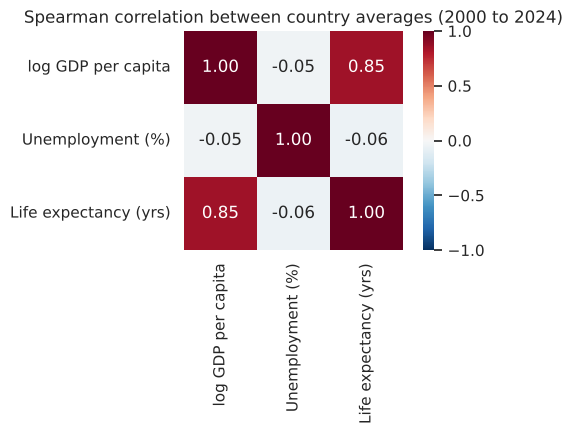

GDP vs life expectancy: n=135, Pearson r=0.80 (p=6.46e-32), Spearman rho=0.85 (p=3.07e-38)
GDP vs unemployment: n=135, Pearson r=-0.11 (p=0.212), Spearman rho=-0.05 (p=0.599)
Unemployment vs life expectancy: n=135, Pearson r=-0.12 (p=0.16), Spearman rho=-0.06 (p=0.48)


In [3]:
cols = {"ln_gdp": "log GDP per capita", "unemp": "Unemployment (%)", "le": "Life expectancy (yrs)"}
corr_matrix = averages[list(cols)].corr(method="spearman").rename(index=cols, columns=cols)
plt.figure(figsize=(6, 4.5))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True)
plt.title("Spearman correlation between country averages (2000 to 2024)")
plt.tight_layout(); plt.show()

def describe_corr(x, y, label):
    r, p = stats.pearsonr(x, y)
    rho, p_s = stats.spearmanr(x, y)
    print(f"{label}: n={len(x)}, Pearson r={r:.2f} (p={p:.3g}), Spearman rho={rho:.2f} (p={p_s:.3g})")

describe_corr(averages["ln_gdp"], averages["le"], "GDP vs life expectancy")
describe_corr(averages["ln_gdp"], averages["unemp"], "GDP vs unemployment")
describe_corr(averages["unemp"], averages["le"], "Unemployment vs life expectancy")


**Q1 findings.** Across countries, GDP per capita and life expectancy are strongly and positively related (Spearman rho = 0.85). Neither GDP per capita nor life expectancy shows a meaningful relationship with unemployment (rho of -0.05 and -0.06, both not significant). Unemployment therefore adds little to the GDP and life-expectancy pattern. These are associations, not causal effects.

## Question 2: Do countries with higher GDP per capita tend to have lower unemployment rates?

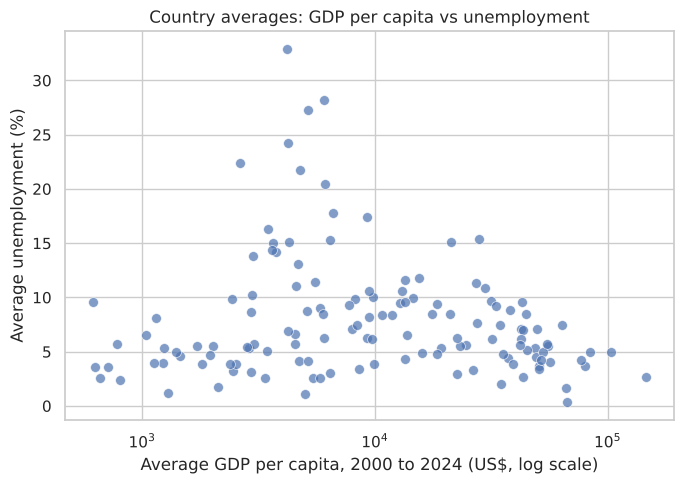

All countries (country averages): n=135, Pearson r=-0.11 (p=0.212), Spearman rho=-0.05 (p=0.599)
                  Countries  Mean unemployment (%)  Median unemployment (%)
Above-median GDP         68                   6.84                     6.19
Below-median GDP         67                   8.89                     6.26


In [4]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=averages, x="gdp", y="unemp", s=50, alpha=0.7)
plt.xscale("log")
plt.xlabel("Average GDP per capita, 2000 to 2024 (US$, log scale)")
plt.ylabel("Average unemployment (%)")
plt.title("Country averages: GDP per capita vs unemployment")
plt.tight_layout(); plt.show()

describe_corr(averages["ln_gdp"], averages["unemp"], "All countries (country averages)")

median_gdp = averages["gdp"].median()
high = averages[averages["gdp"] >= median_gdp]
low = averages[averages["gdp"] < median_gdp]
summary = pd.DataFrame({
    "Countries": [len(high), len(low)],
    "Mean unemployment (%)": [high["unemp"].mean(), low["unemp"].mean()],
    "Median unemployment (%)": [high["unemp"].median(), low["unemp"].median()],
}, index=["Above-median GDP", "Below-median GDP"])
print(summary.round(2))


**Q2 findings.** Across countries, the relationship is weak and not statistically significant (r = -0.11, p = 0.21). Countries above the median GDP per capita have a lower mean unemployment rate (6.8% against 8.9%), but the medians are almost identical (6.2% against 6.3%). The difference in means may be driven by a small number of high-unemployment countries in the lower-GDP group. The data therefore does not show a consistent pattern that richer countries have lower unemployment.

## Question 3: Do countries with higher GDP per capita tend to have longer life expectancy?

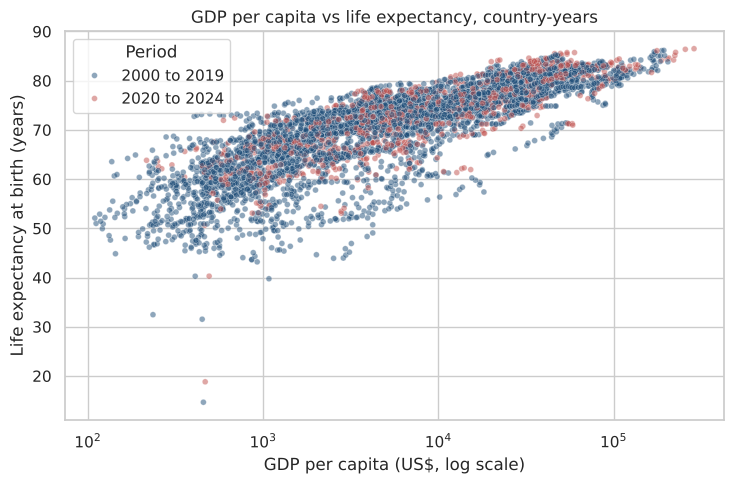

Country averages, 2000 to 2024: n=135, Pearson r=0.80 (p=6.46e-32), Spearman rho=0.85 (p=3.07e-38)
Country-years 2000 to 2019: n=4209, Pearson r=0.82 (p=0), Spearman rho=0.87 (p=0)
Country-years 2020 to 2024: n=1033, Pearson r=0.84 (p=1.48e-271), Spearman rho=0.86 (p=6.8e-305)


In [5]:
full_years = countries.dropna(subset=["gdp", "le"]).copy()
full_years["era"] = np.where(full_years["year"] <= 2019, "2000 to 2019", "2020 to 2024")

plt.figure(figsize=(7.5, 5))
sns.scatterplot(data=full_years, x="gdp", y="le", hue="era", s=18, alpha=0.5, palette=["#1f4e79", "#c0504d"])
plt.xscale("log")
plt.xlabel("GDP per capita (US$, log scale)")
plt.ylabel("Life expectancy at birth (years)")
plt.title("GDP per capita vs life expectancy, country-years")
plt.legend(title="Period")
plt.tight_layout(); plt.show()

describe_corr(averages["ln_gdp"], averages["le"], "Country averages, 2000 to 2024")
for label, part in full_years.groupby("era"):
    describe_corr(part["ln_gdp"], part["le"], f"Country-years {label}")


**Q3 findings.** Higher GDP per capita goes with longer life expectancy. The pattern is strong across country averages (rho = 0.85) and holds in both periods: 2000 to 2019 (rho = 0.87) and 2020 to 2024 (rho = 0.86). The 2020 to 2024 period includes the COVID-19 years, when life expectancy dipped in several countries, but the relationship remains strong. The association is not causal, because income and health are both shaped by other factors such as health systems and education.

## Question 4: Within each country, how do changes in GDP per capita relate to changes in unemployment?
To remove differences between countries, each value is measured as a deviation from that country's own average over 2000 to 2024. A first-difference check, using year-on-year changes, confirms the result.

Within-country deviations: n=3160, Pearson r=-0.29 (p=1.89e-60), Spearman rho=-0.32 (p=2.04e-76)


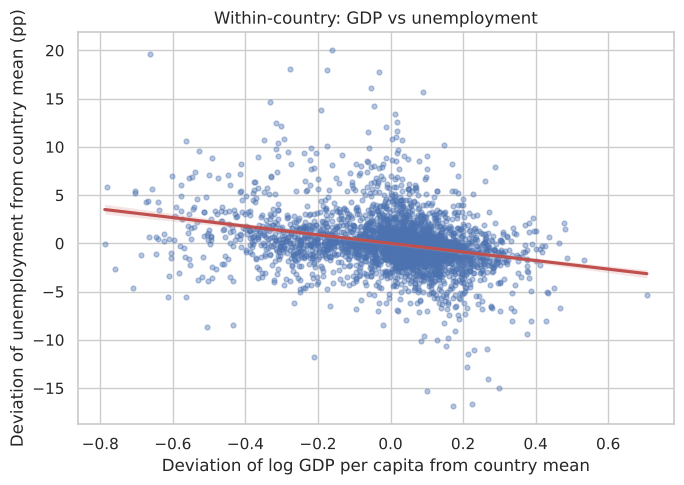

Year-on-year changes: n=2624, Pearson r=-0.19 (p=1.02e-23), Spearman rho=-0.25 (p=1.49e-38)


In [6]:
complete = complete.copy()
complete["gdp_dev"] = complete["ln_gdp"] - complete.groupby("Country Name")["ln_gdp"].transform("mean")
complete["unemp_dev"] = complete["unemp"] - complete.groupby("Country Name")["unemp"].transform("mean")

describe_corr(complete["gdp_dev"], complete["unemp_dev"], "Within-country deviations")

plt.figure(figsize=(7, 5))
sns.regplot(data=complete, x="gdp_dev", y="unemp_dev", scatter_kws={"s": 12, "alpha": 0.4},
            line_kws={"color": "#c0504d"})
plt.xlabel("Deviation of log GDP per capita from country mean")
plt.ylabel("Deviation of unemployment from country mean (pp)")
plt.title("Within-country: GDP vs unemployment")
plt.tight_layout(); plt.show()

# First differences (year-on-year change) as a robustness check
g = countries.sort_values(["Country Name", "year"]).copy()
g["d_ln_gdp"] = g.groupby("Country Name")["ln_gdp"].diff()
g["d_unemp"] = g.groupby("Country Name")["unemp"].diff()
diffs = g.dropna(subset=["d_ln_gdp", "d_unemp"])
describe_corr(diffs["d_ln_gdp"], diffs["d_unemp"], "Year-on-year changes")


**Q4 findings.** Within countries, years with higher GDP per capita tend to have lower unemployment (r = -0.29 on deviations from each country's mean). The year-on-year check gives a weaker but still significant result (r = -0.19), which suggests the link is modest and may reflect slow-moving economic cycles rather than sharp year-to-year responses. Unemployment figures are national estimates with gaps and possible differences in methodology between countries, so these results should be read with caution. Within-country associations are not causal.

## Limitations
- Unemployment uses national estimates (`SL.UEM.TOTL.NE.ZS`), which are less comparable across countries than ILO modeled estimates, and have many missing years.
- Country averages use only countries with at least 10 years of data for each indicator.
- GDP per capita is in current US dollars, so exchange-rate movements affect the series.
- All results are associations found through exploratory analysis. They are not causal.